<sub>**The Annotated ML Handbook** · Part VI: TensorFlow & Keras</sub>

# Chapter 28: Deep learning architectures: CNNs, sequence models and custom training

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mahir-606/annotated-ml-handbook/blob/main/notebooks/part-6-tensorflow-keras/28-keras-advanced.ipynb)

Companion code for the chapter. Every example from the book is here, in order, ready to run. The line-by-line explanations, definitions and discussion are in the book.

Run the setup cell first, then run the cells from top to bottom.

In [1]:
# Repository setup (not part of the book's examples): run this cell first.
import os, sys
from pathlib import Path

# Files the examples create (CSV, models, figures) go into ./outputs next to the notebook.
OUT = Path.cwd() if Path.cwd().name == "outputs" else Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)
os.chdir(OUT)

# insurance.csv is the practice dataset created in Chapter 11 and reused by later chapters.
# If it is not here yet, copy it from the repository's data/ folder (or download it in Colab).
if not Path("insurance.csv").exists():
    import shutil, urllib.request
    for base in OUT.parents:
        if (base / "data" / "insurance.csv").exists():
            shutil.copy(base / "data" / "insurance.csv", "insurance.csv")
            break
    else:
        try:
            urllib.request.urlretrieve("https://raw.githubusercontent.com/Mahir-606/"
                                       "annotated-ml-handbook/main/data/insurance.csv", "insurance.csv")
        except Exception as e:
            print("Could not fetch insurance.csv; run Chapter 11 first.", e)

# The figure style used in the book.
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.28, "grid.linewidth": 0.6,
    "axes.prop_cycle": cycler(color=["#1f4fff", "#e0245e", "#0f9b62", "#ff6a00",
                                     "#7b3ff2", "#0091b3", "#d99a00", "#d42a2a"]),
    "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False, "image.cmap": "viridis",
})

# Plotly: interactive in Jupyter/Colab; tools/run_all.py stores static PNGs so GitHub can show them.
try:
    import plotly.io as pio
    pio.renderers.default = os.environ.get("PLOTLY_RENDERER") or (
        "colab" if "google.colab" in sys.modules else "notebook_connected")
except ImportError:
    pass

## 28.1 Convolutional neural networks · *Intermediate*

**Prepare 8×8 digit images**

In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digits = load_digits()
X = (digits.images / 16.0).astype("float32")
X = X[..., np.newaxis]
y = digits.target
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
print(X_tr.shape, X_te.shape, np.bincount(y_tr))

I0000 00:00:1795691049.404005   27362 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795691050.610809   27362 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


(1437, 8, 8, 1) (360, 8, 8, 1) [142 146 142 146 145 145 145 143 139 144]


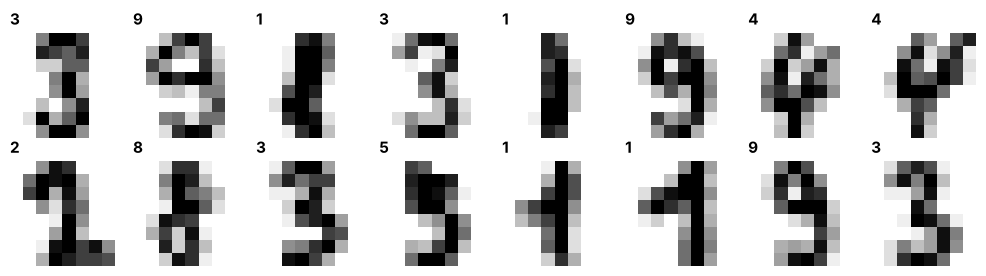

In [3]:
fig, axes = plt.subplots(2, 8, figsize=(10, 2.8))
for ax, img, lab in zip(axes.ravel(), X_tr[:16], y_tr[:16]):
    ax.imshow(img[..., 0], cmap="gray_r"); ax.set_title(str(lab), fontsize=11); ax.axis("off")
plt.tight_layout(); plt.show()

**Build and train a small CNN**

In [4]:
keras.utils.set_random_seed(0)
cnn = keras.Sequential([
    keras.Input(shape=(8, 8, 1)),
    layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
cnn.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn.summary()
hist = cnn.fit(X_tr, y_tr, validation_split=0.15, epochs=40, batch_size=64, verbose=0,
               callbacks=[keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True)])
print("epochs run:", len(hist.history["loss"]), "| test accuracy:", round(cnn.evaluate(X_te, y_te, verbose=0)[1], 4))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 8, 8, 32)       │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 4, 4, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 4, 4, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 2, 2, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,914 (140.29 KB)

 Trainable params: 35,914 (140.29 KB)

 Non-trainable params: 0 (0.00 B)

epochs run: 38 | test accuracy: 0.975


**Where does it go wrong?**

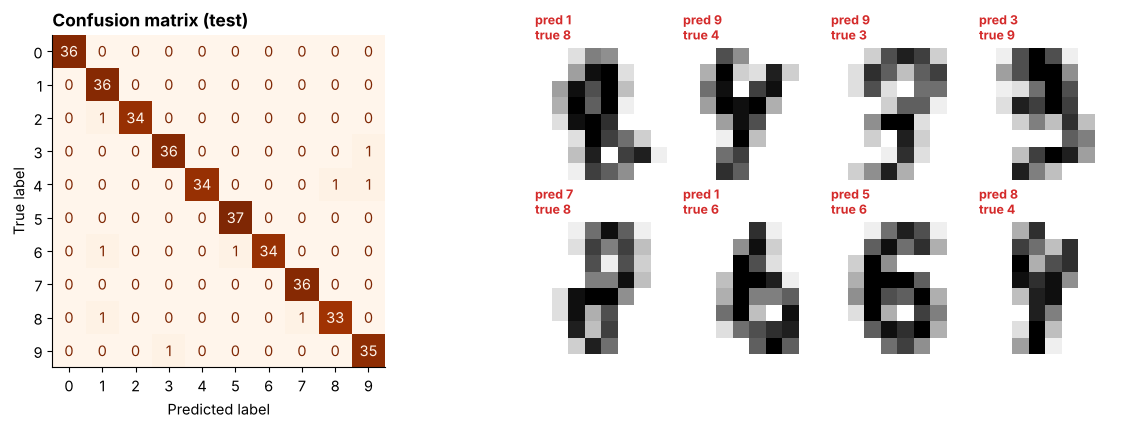

In [5]:
from sklearn.metrics import ConfusionMatrixDisplay
pred = cnn.predict(X_te, verbose=0).argmax(axis=1)
fig = plt.figure(figsize=(12, 4.4))
ax0 = fig.add_subplot(1, 2, 1)
ConfusionMatrixDisplay.from_predictions(y_te, pred, ax=ax0, colorbar=False, cmap="Oranges")
ax0.set_title("Confusion matrix (test)"); ax0.grid(False)
wrong = np.flatnonzero(pred != y_te)[:8]
for k, i in enumerate(wrong):
    ax = fig.add_subplot(2, 8, 5 + k + (4 if k >= 4 else 0))
    ax.imshow(X_te[i, ..., 0], cmap="gray_r"); ax.axis("off")
    ax.set_title(f"pred {pred[i]}\ntrue {y_te[i]}", fontsize=9, color="#d42a2a")
plt.tight_layout()
plt.show()

### 28.1.1 Data augmentation · *Intermediate*

**Augmentation as layers inside the model**

In [6]:
augment = keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomZoom(0.1),
], name="augment")
sample = augment(X_tr[:1].repeat(5, axis=0), training=True)
print(sample.shape)

(5, 8, 8, 1)


## 28.2 Transfer learning · *Advanced*

**Fine-tuning a pretrained image model (downloads weights on first use)**

*Shown for reference, not run automatically (it waits for input, needs your own files, or would change your system). Copy it into a cell to try it.*

```python
base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet",
                                         input_shape=(224, 224, 3))
base.trainable = False
inputs = keras.Input(shape=(224, 224, 3))
x = augment(inputs)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(n_classes, activation="softmax")(x)
model = keras.Model(inputs, outputs)
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.fit(train_ds, validation_data=val_ds, epochs=10)
base.trainable = True
model.compile(optimizer=keras.optimizers.Adam(1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.fit(train_ds, validation_data=val_ds, epochs=5)
```

## 28.3 Sequence models: forecasting a time series · *Intermediate*

**Windowed data from a noisy seasonal series**

In [7]:
keras.utils.set_random_seed(0)
t = np.arange(1200, dtype="float32")
series = (np.sin(2 * np.pi * t / 50) + 0.5 * np.sin(2 * np.pi * t / 17)
          + 0.001 * t + np.random.default_rng(0).normal(0, 0.15, t.size)).astype("float32")
split = 1000
mean, std = series[:split].mean(), series[:split].std()
s = (series - mean) / std
window = 40

def make_ds(arr, shuffle):
    return keras.utils.timeseries_dataset_from_array(
        data=arr[:-1], targets=arr[window:],
        sequence_length=window, batch_size=32, shuffle=shuffle, seed=0)

train_ds = make_ds(s[:split], shuffle=True)
test_ds = make_ds(s[split - window:], shuffle=False)
xb, yb = next(iter(train_ds))
print(xb.shape, yb.shape)

(32, 40) (32,)


**LSTM vs 1-D CNN vs a naive baseline**

In [8]:
def train(model):
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    model.fit(train_ds, epochs=30, verbose=0, shuffle=False)
    return model

lstm = train(keras.Sequential([keras.Input(shape=(window,)),
                               layers.Reshape((window, 1)),
                               layers.LSTM(32),
                               layers.Dense(1)]))
conv = train(keras.Sequential([keras.Input(shape=(window,)),
                               layers.Reshape((window, 1)),
                               layers.Conv1D(32, kernel_size=5, activation="relu"),
                               layers.Flatten(),
                               layers.Dense(1)]))
y_test = np.concatenate([y.numpy() for _, y in test_ds])
naive = s[split - 1:-1]
rmse = lambda p: float(np.sqrt(np.mean((p - y_test) ** 2)) * std)
p_lstm = lstm.predict(test_ds, verbose=0).ravel()
p_conv = conv.predict(test_ds, verbose=0).ravel()
print(f"test RMSE  naive={rmse(naive):.3f}  LSTM={rmse(p_lstm):.3f}  Conv1D={rmse(p_conv):.3f}")

test RMSE  naive=0.260  LSTM=0.210  Conv1D=0.160


**Forecasts against the truth**

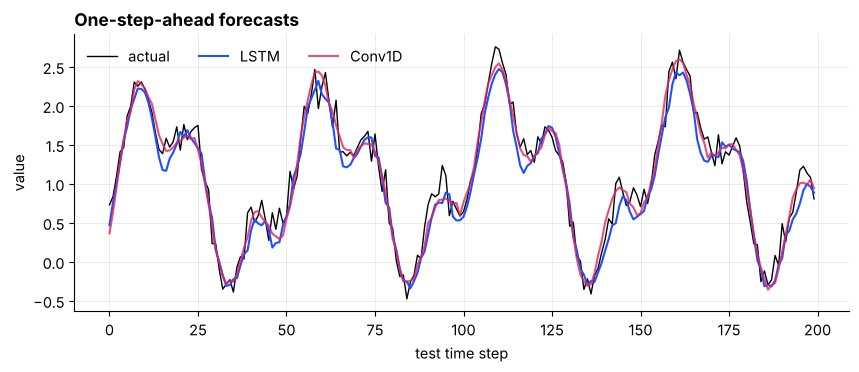

In [9]:
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(y_test * std + mean, color="black", lw=1, label="actual")
ax.plot(p_lstm * std + mean, label="LSTM")
ax.plot(p_conv * std + mean, label="Conv1D", alpha=0.8)
ax.set(xlabel="test time step", ylabel="value", title="One-step-ahead forecasts")
ax.legend(ncol=3)
plt.show()

## 28.4 Custom training loops · *Advanced*

**A complete custom loop**

In [10]:
keras.utils.set_random_seed(0)
model = keras.Sequential([keras.Input(shape=(8, 8, 1)), layers.Flatten(),
                          layers.Dense(64, activation="relu"), layers.Dense(10)])
loss_fn = keras.losses.SparseCategoricalCrossentropy(from_logits=True)
optimizer = keras.optimizers.Adam(1e-3)
train_acc = keras.metrics.SparseCategoricalAccuracy()
ds = tf.data.Dataset.from_tensor_slices((X_tr, y_tr)).shuffle(2000, seed=0).batch(64)

@tf.function
def train_step(xb, yb):
    with tf.GradientTape() as tape:
        logits = model(xb, training=True)
        loss = loss_fn(yb, logits)
    grads = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(grads, model.trainable_variables))
    train_acc.update_state(yb, logits)
    return loss

for epoch in range(5):
    train_acc.reset_state()
    for xb, yb in ds:
        loss = train_step(xb, yb)
    print(f"epoch {epoch + 1}: loss={float(loss):.4f}  train acc={float(train_acc.result()):.4f}")
test_logits = model(X_te, training=False)
print("test accuracy:", round(float(np.mean(np.argmax(test_logits, axis=1) == y_te)), 4))

epoch 1: loss=1.9745  train acc=0.2248
epoch 2: loss=1.7470  train acc=0.6131
epoch 3: loss=1.2736  train acc=0.7655
epoch 4: loss=1.0847  train acc=0.8358


epoch 5: loss=0.8528  train acc=0.8692
test accuracy: 0.8861


## 28.5 Other architectures in one table · *Intermediate*

## Try it yourself

1. Add the `augment` block as the first layer of the CNN and compare test accuracy.
2. Replace `LSTM(32)` with `GRU(32)`, and try `window = 10` and `window = 80`.
3. Turn the forecaster into a 5-step-ahead model by changing the targets and using `Dense(5)`.

Worked solutions: [solutions-parts-5-8.ipynb](../../solutions/solutions-parts-5-8.ipynb), section *Chapter 28*.